# Rozdział 6 — Predykcja churnu
Definicja churnu, podział czasowy, cechy, modele (LR + RF), metryki, SHAP, zapis wyników.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, f1_score, classification_report,
    confusion_matrix, RocCurveDisplay
)
from sklearn.preprocessing import StandardScaler
import shap
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
plt.rcParams.update({'figure.dpi': 150, 'font.size': 11})

# Wczytanie danych
df_clean = pd.read_csv('online_retail_clean.csv',
                       parse_dates=['InvoiceDate'])
rfm = pd.read_csv('rfm_features.csv')
clusters = pd.read_csv('cluster_labels.csv')

print(f'Transakcji: {len(df_clean)}')
print(f'Klientów (RFM): {len(rfm)}')
print(f'Zakres dat: {df_clean["InvoiceDate"].min().date()} — {df_clean["InvoiceDate"].max().date()}')

Transakcji: 801291
Klientów (RFM): 5859
Zakres dat: 2009-12-01 — 2011-12-09


## 1. Definicja churnu — okno czasowe d=90 dni

In [2]:
CUTOFF_DATE = pd.Timestamp('2011-09-01')
CHURN_DAYS = 90

# Ostatni zakup każdego klienta PRZED datą odcięcia
df_train_raw = df_clean[df_clean['InvoiceDate'] < CUTOFF_DATE]
df_test_raw  = df_clean[df_clean['InvoiceDate'] >= CUTOFF_DATE]

last_purchase_before = (
    df_train_raw.groupby('Customer ID')['InvoiceDate'].max()
    .reset_index()
    .rename(columns={'InvoiceDate': 'last_purchase'})
)

# Klienci aktywni w oknie testowym
active_in_test = set(df_test_raw['Customer ID'].unique())

# Tylko klientów widocznych przed cutoff
churn_df = last_purchase_before.copy()
churn_df['days_since_last'] = (
    CUTOFF_DATE - churn_df['last_purchase']
).dt.days

# Definicja churnu:
# churn = 1 jeśli klient NIE kupił niczego >= CUTOFF_DATE
# ORAZ jego ostatni zakup był >= CHURN_DAYS dni przed CUTOFF
churn_df['churn'] = (
    (~churn_df['Customer ID'].isin(active_in_test)) &
    (churn_df['days_since_last'] >= CHURN_DAYS)
).astype(int)

churn_rate = churn_df['churn'].mean()
print(f'Cutoff date:  {CUTOFF_DATE.date()}')
print(f'Churn days:   {CHURN_DAYS}')
print(f'\nKlientów w zbiorze churn: {len(churn_df)}')
print(f'  Churned (y=1): {churn_df["churn"].sum()} ({churn_rate:.1%})')
print(f'  Active  (y=0): {(churn_df["churn"]==0).sum()} ({1-churn_rate:.1%})')

Cutoff date:  2011-09-01
Churn days:   90

Klientów w zbiorze churn: 5230
  Churned (y=1): 2332 (44.6%)
  Active  (y=0): 2898 (55.4%)


## 2. Budowa zbioru cech i podział na train/test

In [3]:
# Cechy RFM i behawioralne obliczone OD NOWA wyłącznie na transakcjach
# sprzed daty odcięcia (df_train_raw), aby uniknąć wycieku informacji
# (data leakage) — patrz sekcja 6.1.2. Recency liczone względem CUTOFF_DATE,
# a nie względem końca całego zbioru jak w rozdz. 4 (tam: rfm_features.csv).

snapshot_date = CUTOFF_DATE

rfm_pre = df_train_raw.groupby('Customer ID').agg(
    Recency   = ('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('Invoice', 'nunique'),
    Monetary  = ('TotalPrice', 'sum')
).reset_index()

rfm_pre_extra = df_train_raw.groupby('Customer ID').agg(
    ProductDiversity = ('StockCode', 'nunique'),
    AvgOrderValue    = ('TotalPrice', lambda x: x.sum() / df_train_raw.loc[x.index, 'Invoice'].nunique()),
    PreferredHour    = ('InvoiceDate', lambda x: x.dt.hour.mode()[0]),
    PreferredDay     = ('InvoiceDate', lambda x: x.dt.dayofweek.mode()[0])
).reset_index()

rfm_pre = rfm_pre.merge(rfm_pre_extra, on='Customer ID')

avg_days_pre = df_train_raw.groupby('Customer ID').apply(
    lambda x: x.drop_duplicates('Invoice')
               .sort_values('InvoiceDate')['InvoiceDate']
               .diff()
               .dt.days
               .mean()
).reset_index()
avg_days_pre.columns = ['Customer ID', 'AvgDaysBetweenPurchases']
rfm_pre = rfm_pre.merge(avg_days_pre, on='Customer ID')
rfm_pre['AvgDaysBetweenPurchases'] = rfm_pre['AvgDaysBetweenPurchases'].fillna(rfm_pre['Recency'])

# Połącz cechy pre-cutoff z etykietą churnu (bez cluster_kmeans —
# etykieta skupiska z rozdz. 5 pochodzi z pełnego okresu i również
# stanowiłaby wyciek informacji; zbiór cech = 8 wejść jak w sekcji 6.1.2)
data = churn_df.merge(rfm_pre, on='Customer ID', how='left')

FEATURE_COLS = [
    'Recency', 'Frequency', 'Monetary',
    'ProductDiversity', 'AvgOrderValue',
    'PreferredHour', 'PreferredDay',
    'AvgDaysBetweenPurchases'
]
TARGET = 'churn'

data = data.dropna(subset=FEATURE_COLS + [TARGET])
print(f'Próbek po łączeniu: {len(data)}')

# Podział czasowy:
#   train = klienci z ostatnim zakupem < CUTOFF
#   test  = klienci aktywni >= CUTOFF (obserwowani w oknie testowym)
# Podejście: wszystkich klientów PRZED cutoff do train,
# sprawdzamy ich status churnu na podstawie okna testowego.
# Stosujemy podział 80/20 ze stratyfikacją, bo brak naturalnego
# zbioru testowego dla tej definicji churnu.

from sklearn.model_selection import train_test_split

X_all = data[FEATURE_COLS].values
y_all = data[TARGET].values

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_all
)

# Skalowanie (osobne dla train/test — bez data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f'\nTrain: {X_train.shape[0]} próbek  |  churn rate: {y_train.mean():.1%}')
print(f'Test:  {X_test.shape[0]} próbek   |  churn rate: {y_test.mean():.1%}')

Próbek po łączeniu: 5230

Train: 4184 próbek  |  churn rate: 44.6%
Test:  1046 próbek   |  churn rate: 44.6%


## 3. Regresja logistyczna (baseline)

In [4]:
lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=RANDOM_STATE,
    C=1.0
)
lr.fit(X_train_s, y_train)
y_pred_lr  = lr.predict(X_test_s)
y_prob_lr  = lr.predict_proba(X_test_s)[:, 1]

auc_lr = roc_auc_score(y_test, y_prob_lr)
f1_lr  = f1_score(y_test, y_pred_lr)

print('=== REGRESJA LOGISTYCZNA ===')
print(f'AUC-ROC: {auc_lr:.4f}')
print(f'F1:      {f1_lr:.4f}')
print()
print(classification_report(y_test, y_pred_lr,
                             target_names=['active', 'churned']))

=== REGRESJA LOGISTYCZNA ===
AUC-ROC: 0.8809
F1:      0.7891

              precision    recall  f1-score   support

      active       0.84      0.80      0.82       580
     churned       0.77      0.81      0.79       466

    accuracy                           0.81      1046
   macro avg       0.80      0.81      0.81      1046
weighted avg       0.81      0.81      0.81      1046



## 4. Las losowy

In [5]:
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    max_features='sqrt',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)  # RF nie wymaga skalowania
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

auc_rf = roc_auc_score(y_test, y_prob_rf)
f1_rf  = f1_score(y_test, y_pred_rf)

print('=== LAS LOSOWY ===')
print(f'AUC-ROC: {auc_rf:.4f}')
print(f'F1:      {f1_rf:.4f}')
print()
print(classification_report(y_test, y_pred_rf,
                             target_names=['active', 'churned']))

=== LAS LOSOWY ===
AUC-ROC: 0.8974
F1:      0.8117

              precision    recall  f1-score   support

      active       0.90      0.75      0.82       580
     churned       0.74      0.90      0.81       466

    accuracy                           0.81      1046
   macro avg       0.82      0.82      0.81      1046
weighted avg       0.83      0.81      0.81      1046



## 5. Krzywe ROC oraz macierze pomyłek

Krzywe ROC trafiaja do pracy jako osobny rysunek o~szerokosci ok. 55%
kolumny tekstu, macierze pomylek zostaja podane w~formie tabeli
(zamiast nieczytelnych w~druku heatmap) — liczby wypisane nizej.


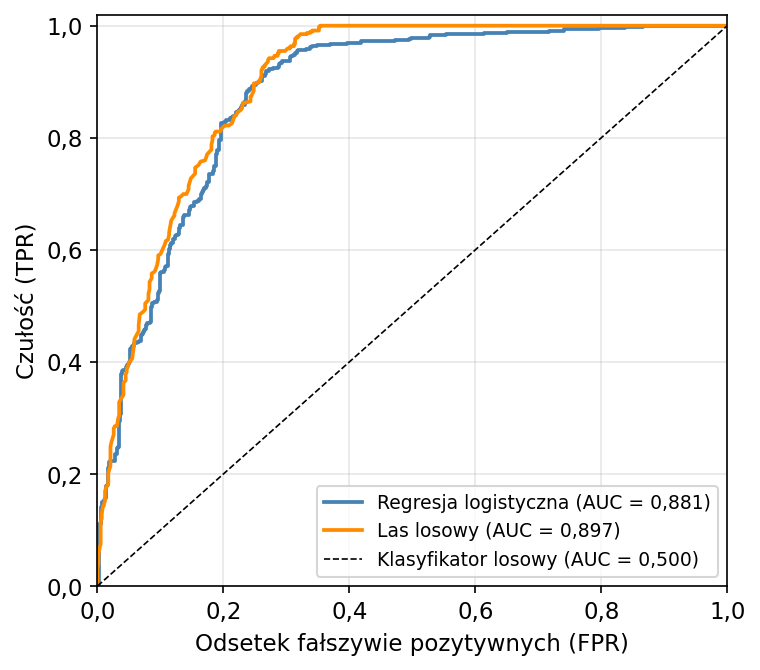

Zapisano: fig_roc.png

=== MACIERZE POMYLEK (zbior testowy) ===
Regresja logistyczna:
  rzeczywiste 0 (aktywny):    TN =  466   FP =  114
  rzeczywiste 1 (rezygnacja): FN =   88   TP =  378
  n = 1046, dokladnosc = 0.8069
Las losowy:
  rzeczywiste 0 (aktywny):    TN =  434   FP =  146
  rzeczywiste 1 (rezygnacja): FN =   48   TP =  418
  n = 1046, dokladnosc = 0.8145


In [6]:
from sklearn.metrics import roc_curve
from matplotlib.ticker import FuncFormatter

# ---------- Krzywe ROC: osobny rysunek ----------
przecinek = FuncFormatter(lambda v, _: f'{v:.1f}'.replace('.', ','))

fig, ax = plt.subplots(figsize=(5.2, 4.6))
for y_prob, auc, etykieta, kolor in [
    (y_prob_lr, auc_lr, 'Regresja logistyczna', 'steelblue'),
    (y_prob_rf, auc_rf, 'Las losowy',           'darkorange'),
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    ax.plot(fpr, tpr, color=kolor, linewidth=1.8,
            label=f'{etykieta} (AUC = ' + f'{auc:.3f}'.replace('.', ',') + ')')

ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8,
        label='Klasyfikator losowy (AUC = 0,500)')
ax.set_xlabel('Odsetek fałszywie pozytywnych (FPR)')
ax.set_ylabel('Czułość (TPR)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(przecinek)
ax.yaxis.set_major_formatter(przecinek)
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_roc.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_roc.png')

# ---------- Macierze pomylek: liczby do tabeli w pracy ----------
print()
print('=== MACIERZE POMYLEK (zbior testowy) ===')
for nazwa, y_pred in [('Regresja logistyczna', y_pred_lr),
                      ('Las losowy',           y_pred_rf)]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    n = tn + fp + fn + tp
    print(f'{nazwa}:')
    print(f'  rzeczywiste 0 (aktywny):    TN = {tn:4d}   FP = {fp:4d}')
    print(f'  rzeczywiste 1 (rezygnacja): FN = {fn:4d}   TP = {tp:4d}')
    print(f'  n = {n}, dokladnosc = {(tp + tn) / n:.4f}')


## 6. Wartości SHAP — ważność cech lasu losowego

In [7]:
# SHAP TreeExplainer (dla RF — bez skalowania)
explainer = shap.TreeExplainer(rf)

sample_size = min(500, len(X_test))
idx_sample = np.random.RandomState(RANDOM_STATE).choice(
    len(X_test), sample_size, replace=False
)
X_shap = X_test[idx_sample]

shap_values_raw = explainer.shap_values(X_shap)

# Normalizacja do 2D array (n_samples, n_features) dla klasy 1 (churned):
#   SHAP < 0.41  → lista [array(n,d), array(n,d)]  → bierzemy [1]
#   SHAP >= 0.41 → array(n, d, n_classes)            → bierzemy [:, :, 1]
#   Inne         → array(n, d)                        → zostawiamy
if isinstance(shap_values_raw, list):
    shap_vals = np.array(shap_values_raw[1])
else:
    sv = np.array(shap_values_raw)
    if sv.ndim == 3:
        shap_vals = sv[:, :, 1]
    else:
        shap_vals = sv

assert shap_vals.ndim == 2, \
    f"Nieoczekiwany kształt shap_vals: {shap_vals.shape}"

print(f"SHAP obliczone dla {sample_size} obserwacji.")
print(f"shap_vals.shape = {shap_vals.shape}  "
      f"(oczekiwane: ({sample_size}, {len(FEATURE_COLS)}))")

SHAP obliczone dla 500 obserwacji.
shap_vals.shape = (500, 8)  (oczekiwane: (500, 8))


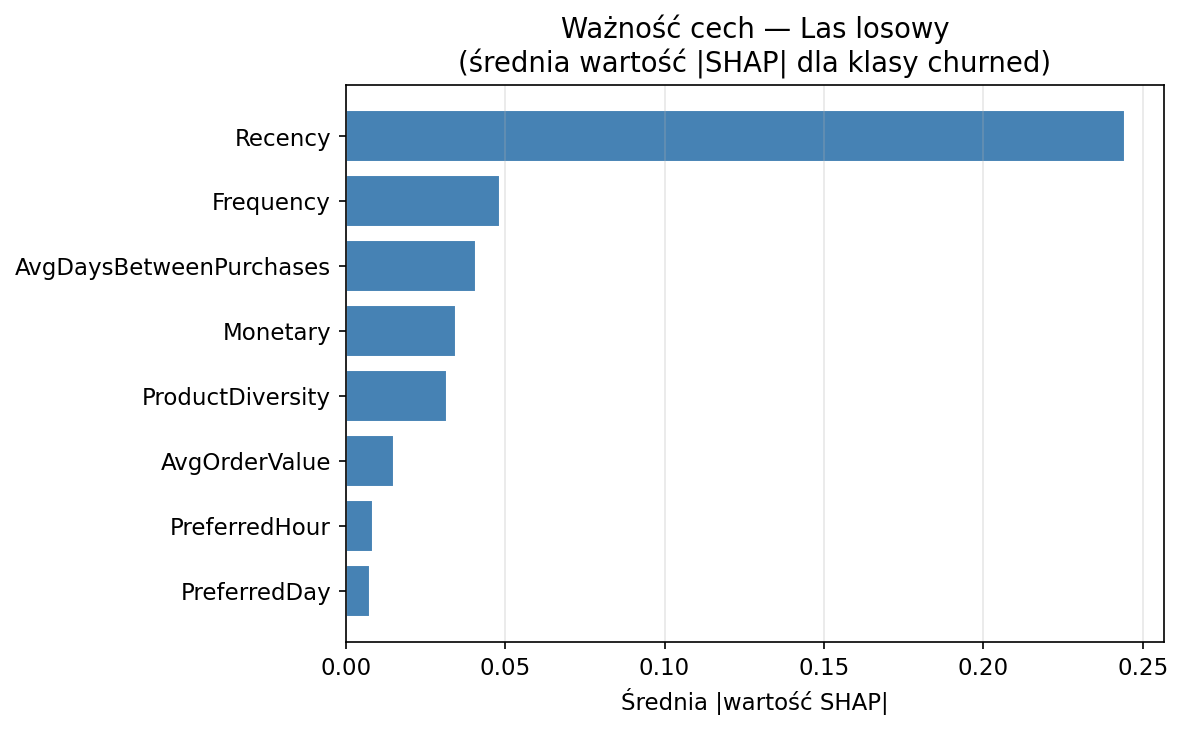

Zapisano: fig_shap_bar.png

Srednia |SHAP| (malejaco):
  Recency                   0.2444
  Frequency                 0.0482
  AvgDaysBetweenPurchases   0.0409
  Monetary                  0.0346
  ProductDiversity          0.0317
  AvgOrderValue             0.0151
  PreferredHour             0.0087
  PreferredDay              0.0078
  stosunek Recency/Frequency = 5.07x


In [8]:
# Wykres ważności cech (bar plot — średnia |SHAP|)
mean_shap = np.abs(shap_vals).mean(axis=0)

# Upewniamy się że mean_shap jest 1D
if mean_shap.ndim > 1:
    mean_shap = mean_shap.ravel()

shap_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'mean_abs_shap': mean_shap
}).sort_values('mean_abs_shap', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(shap_df['feature'], shap_df['mean_abs_shap'],
        color='steelblue', edgecolor='white')
ax.set_title('Ważność cech — Las losowy\n(średnia wartość |SHAP| dla klasy churned)')
ax.set_xlabel('Średnia |wartość SHAP|')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_shap_bar.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_shap_bar.png')

# Wartosci cytowane w rozdz. 6.4 pracy
print()
print('Srednia |SHAP| (malejaco):')
for k, v in shap_df.sort_values('mean_abs_shap', ascending=False).set_index('feature')['mean_abs_shap'].items():
    print(f'  {k:<26}{v:.4f}')
print(f'  stosunek Recency/Frequency = {shap_df["mean_abs_shap"].max() / sorted(shap_df["mean_abs_shap"])[-2]:.2f}x')

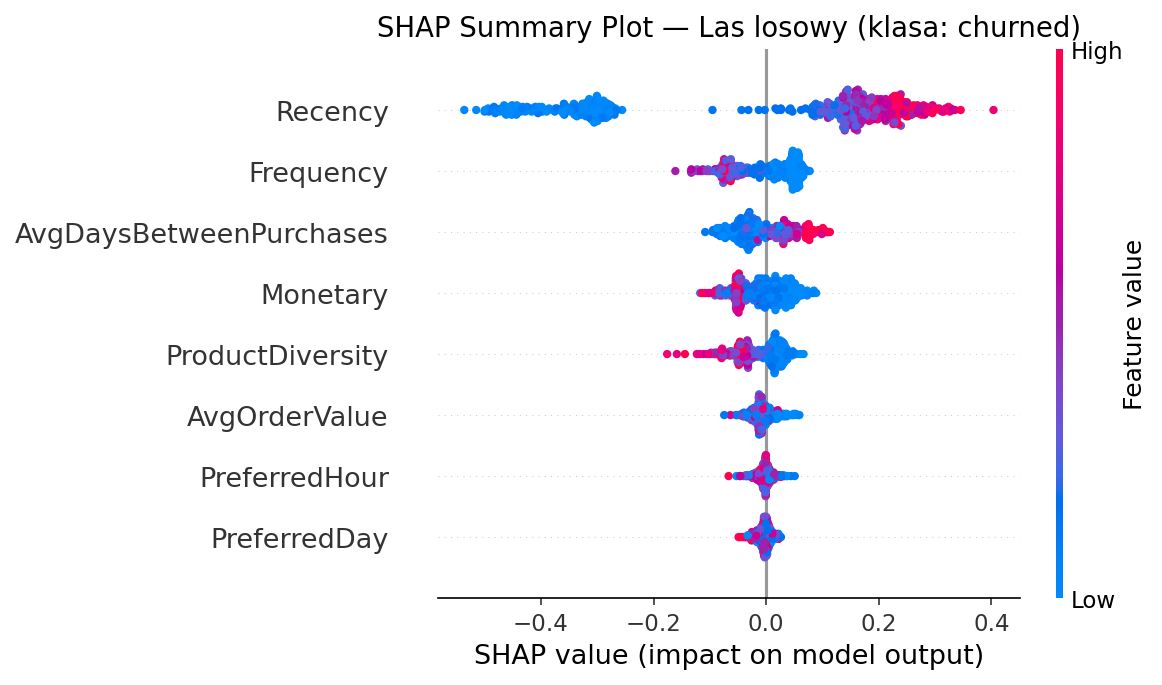

Zapisano: fig_shap_summary.png


In [9]:
# Beeswarm / summary plot SHAP
plt.figure(figsize=(9, 5))
shap.summary_plot(
    shap_vals, X_shap,
    feature_names=FEATURE_COLS,
    show=False
)
plt.title('SHAP Summary Plot — Las losowy (klasa: churned)')
plt.tight_layout()
plt.savefig('fig_shap_summary.png', bbox_inches='tight')
plt.show()
print('Zapisano: fig_shap_summary.png')

## 7. Zestawienie wyników i zapis

In [10]:
from sklearn.metrics import precision_score, recall_score

results = pd.DataFrame({
    'Model': ['Regresja logistyczna', 'Las losowy'],
    'AUC-ROC': [round(auc_lr, 4), round(auc_rf, 4)],
    'F1': [round(f1_lr, 4), round(f1_rf, 4)],
    'Precyzja': [
        round(precision_score(y_test, y_pred_lr), 4),
        round(precision_score(y_test, y_pred_rf), 4)
    ],
    'Czulosc': [
        round(recall_score(y_test, y_pred_lr), 4),
        round(recall_score(y_test, y_pred_rf), 4)
    ]
})

print('=== ZESTAWIENIE WYNIKÓW ===')
print(results.to_string(index=False))

# Zapis predykcji
pred_df = pd.DataFrame({
    'Customer ID': data['Customer ID'].values,
    'y_true': y_all,
    'y_pred_lr': lr.predict(scaler.transform(X_all)),
    'y_prob_lr': lr.predict_proba(scaler.transform(X_all))[:, 1],
    'y_pred_rf': rf.predict(X_all),
    'y_prob_rf': rf.predict_proba(X_all)[:, 1]
})
pred_df.to_csv('churn_predictions.csv', index=False)
results.to_csv('churn_results.csv', index=False)
print('\nZapisano: churn_predictions.csv, churn_results.csv')

=== ZESTAWIENIE WYNIKÓW ===
               Model  AUC-ROC     F1  Precyzja  Czulosc
Regresja logistyczna   0.8809 0.7891    0.7683   0.8112
          Las losowy   0.8974 0.8117    0.7411   0.8970

Zapisano: churn_predictions.csv, churn_results.csv


## 8. Analiza diagnostyczna — rozdz. 6.5

Definicja rezygnacji zawiera warunek `Recency >= CHURN_DAYS`, wobec czego
zachodzi implikacja `Recency < 90  =>  y = 0`. Poniższe cztery analizy
pozwalają oddzielić rzeczywistą zdolność predykcyjną modeli od tego
efektu definicyjnego. Wyniki trafiają do tabel 6.1 i 6.2 pracy.

In [11]:
from sklearn.metrics import accuracy_score

R_IDX = FEATURE_COLS.index('Recency')
R_test = X_test[:, R_IDX]

def metryki(y_true, y_pred, y_score):
    return dict(
        auc=roc_auc_score(y_true, y_score),
        f1=f1_score(y_true, y_pred),
        prec=precision_score(y_true, y_pred),
        rec=recall_score(y_true, y_pred),
        acc=accuracy_score(y_true, y_pred),
    )

wiersze = {}

# --- 0. Kontrola determinizmu etykiety -----------------------------------
maska_low = X_all[:, R_IDX] < CHURN_DAYS
print('=== Determinizm etykiety ===')
print(f'  klientów z Recency < {CHURN_DAYS}: {int(maska_low.sum())} '
      f'({maska_low.mean():.1%} zbioru)')
print(f'  z nich oznaczonych jako rezygnacja: {int(y_all[maska_low].sum())}')

# --- 1. Reguła progowa Recency >= 90 (bez uczenia) -----------------------
pred_regula = (R_test >= CHURN_DAYS).astype(int)
wiersze['Reguła progowa R >= 90'] = metryki(y_test, pred_regula, R_test)

# --- 2. Las losowy na pełnym zbiorze testowym (odniesienie) --------------
wiersze['Las losowy (pełny zbiór)'] = metryki(y_test, y_pred_rf, y_prob_rf)

# --- 3. Las losowy oceniony tylko na podgrupie Recency >= 90 -------------
m = R_test >= CHURN_DAYS
wiersze[f'Las losowy | podgrupa R >= 90 (n={int(m.sum())})'] = metryki(
    y_test[m], y_pred_rf[m], y_prob_rf[m])

# --- 4. Las losowy bez cechy Recency -------------------------------------
kol = [i for i in range(len(FEATURE_COLS)) if i != R_IDX]
rf_bez_R = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', max_features='sqrt',
    random_state=RANDOM_STATE, n_jobs=-1).fit(X_train[:, kol], y_train)
wiersze['Las losowy bez cechy Recency'] = metryki(
    y_test, rf_bez_R.predict(X_test[:, kol]),
    rf_bez_R.predict_proba(X_test[:, kol])[:, 1])

# --- 5. Regresja logistyczna na cechach po transformacji log1p -----------
# Kontrola: czy przewaga lasu wynika z nieliniowości, czy z braku log1p
# (w rozdz. 5 cechy skośne poddano transformacji log1p, tutaj nie).
SKOSNE = ['Recency', 'Frequency', 'Monetary', 'ProductDiversity',
          'AvgOrderValue', 'AvgDaysBetweenPurchases']
idx_skosne = [FEATURE_COLS.index(c) for c in SKOSNE]
Xtr_log, Xte_log = X_train.copy(), X_test.copy()
Xtr_log[:, idx_skosne] = np.log1p(Xtr_log[:, idx_skosne])
Xte_log[:, idx_skosne] = np.log1p(Xte_log[:, idx_skosne])
sc_log = StandardScaler().fit(Xtr_log)
lr_log = LogisticRegression(class_weight='balanced', max_iter=1000,
                            random_state=RANDOM_STATE, C=1.0
                            ).fit(sc_log.transform(Xtr_log), y_train)
wiersze['Reg. logistyczna + log1p'] = metryki(
    y_test, lr_log.predict(sc_log.transform(Xte_log)),
    lr_log.predict_proba(sc_log.transform(Xte_log))[:, 1])
wiersze['Reg. logistyczna (bez log1p)'] = metryki(y_test, y_pred_lr, y_prob_lr)

# --- zestawienie ---------------------------------------------------------
diag = pd.DataFrame(wiersze).T.round(4)
diag.columns = ['AUC-ROC', 'F1', 'Precyzja', 'Czułość', 'Dokładność']
print('\n=== ANALIZA DIAGNOSTYCZNA (zbiór testowy) ===')
print(diag.to_string())
diag.to_csv('churn_diagnostyka.csv')
print('\nZapisano: churn_diagnostyka.csv')

=== Determinizm etykiety ===
  klientów z Recency < 90: 1916 (36.6% zbioru)
  z nich oznaczonych jako rezygnacja: 0



=== ANALIZA DIAGNOSTYCZNA (zbiór testowy) ===
                                       AUC-ROC      F1  Precyzja  Czułość  Dokładność
Reguła progowa R >= 90                  0.8828  0.8183    0.6924   1.0000      0.8021
Las losowy (pełny zbiór)                0.8974  0.8117    0.7411   0.8970      0.8145
Las losowy | podgrupa R >= 90 (n=673)   0.7125  0.8117    0.7411   0.8970      0.7117
Las losowy bez cechy Recency            0.8312  0.7060    0.7060   0.7060      0.7380
Reg. logistyczna + log1p                0.8919  0.8083    0.7523   0.8734      0.8155
Reg. logistyczna (bez log1p)            0.8809  0.7891    0.7683   0.8112      0.8069

Zapisano: churn_diagnostyka.csv
